#### Load Packages

In [8]:
#install dependencies b/c enviornment/kernel has not yet been set up
#uncomment to run

#%pip install pandas numpy rdkit matplotlib seaborn scikit=learn xgboost


In [9]:
#Basic
import os
import pandas as pd
import numpy as np

#Chem
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, PandasTools, rdFingerprintGenerator
from rdkit.DataStructs import TanimotoSimilarity

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Set up a consistent plotting style
plt.style.use("default")
sns.set_palette("husl")

# Modeling Training and Evaluation
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import (make_scorer, matthews_corrcoef, classification_report, roc_curve, auc, 
                             accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, 
                             multilabel_confusion_matrix, ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.base import clone

# Jupyter command to make more than one output show up
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [10]:
# Set Random Seed for Reproducibility
RANDOM_SEED = 1147 
np.random.seed(RANDOM_SEED)

#### Load Dataset

In [11]:
#url = "https://zenodo.org/records/11062077/files/dataset_final.csv?download=1"
#df = pd.read_csv("~/data/raw/apistox_full_raw.csv")

DATA_DIR = "../data/raw"
DATA_FILE = os.path.join(DATA_DIR, "apistox_full_raw.csv")
df = pd.read_csv(DATA_FILE)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1


Shape: (1035, 13)
Columns: ['name', 'CID', 'CAS', 'SMILES', 'source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label', 'ppdb_level']


In [12]:
# create DATA_FILE for other 6 datasets
DATA_FILE1 = os.path.join(DATA_DIR, "random_train_raw.csv")
DATA_FILE2 = os.path.join(DATA_DIR, "random_test_raw.csv")
DATA_FILE3 = os.path.join(DATA_DIR, "maxmin_train_raw.csv")
DATA_FILE4 = os.path.join(DATA_DIR, "maxmin_test_raw.csv")
DATA_FILE5 = os.path.join(DATA_DIR, "time_train_raw.csv")
DATA_FILE6 = os.path.join(DATA_DIR, "time_test_raw.csv")


### EDA
(1) Creating Features

(2) Correlation Analysis

(3) Tanimoto Similarity

In [13]:
### Create Fingerprints ###
#add 'mol' molecule type as a new column to the dataframe
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='SMILES', molCol='molecule')

#create a morgan fingerprints data frame
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# Generate fingerprints for all molecules
fingerprints = []
for mol in df['molecule']:
    fp = morgan_gen.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

# Convert to DataFrame with indexed column names
fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=df.index)
df_fp = pd.concat([df, fingerprint_df], axis=1)

print(f"Dataframe of fingerprints shape: {fingerprint_df.shape}")

#find the number of bits on for each MorganFP


#calculte the mean and sd of the tanimoto similarities for the three classes

#create two filtered dataframes for nontoxic and toxic

nontox_df = df[df['ppdb_level'] == 0]
toxic_df = df[df['ppdb_level'] == 2]

print(len(nontox_df), len(toxic_df))
df_fp.shape

Dataframe of fingerprints shape: (1035, 2048)
177 171


(1035, 2062)

In [14]:
### Computing Tanimoto Similarity ###
def compare_fp_parameters(mols, molecule_names, radius, fp_size, column):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=fp_size
    )
    fingerprints = [generator.GetFingerprint(mol) for mol in column]

    matrix = []
    for fp_a in fingerprints:
        row = [
            TanimotoSimilarity(fp_a, fp_b)
            for fp_b in fingerprints
        ]
        matrix.append(row)

    return pd.DataFrame(matrix)
mols_nontox = nontox_df['molecule'].tolist() #.iloc[:177].tolist()
names_nontox = nontox_df['name'].tolist() #[:177].astype(str).tolist()

print(len(mols_nontox), len(names_nontox))

177 177


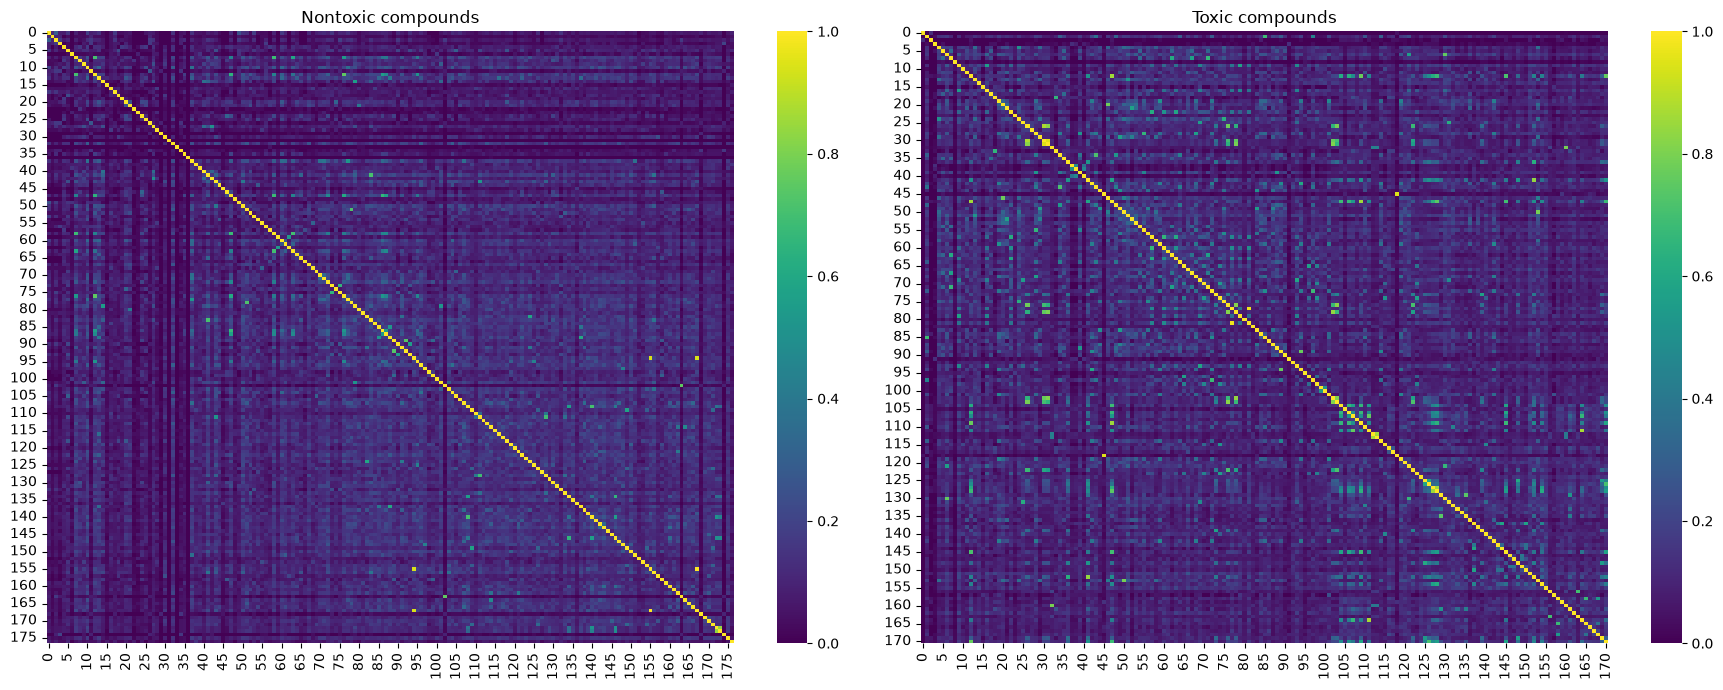

In [15]:
### Plot Similarities in Nontoxic and Toxic ###
similarity_nontox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = nontox_df['molecule']) 
similarity_tox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = toxic_df['molecule'])
fig, axes = plt.subplots(1, 2, figsize=(18, 7)) # plot matrices side-by-side

sns.heatmap(similarity_nontox, ax=axes[0], cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Nontoxic compounds")

sns.heatmap(similarity_tox, ax=axes[1], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Toxic compounds")

plt.tight_layout()
plt.show();

### Train/Test Split
The ApisTox dataset comes with three prepared train-test splits to encourage benchmarking and collaboration with the dataset. The Train/Test is split 80-20. The splits were prepared with different validation goals in mind: two are interpolative and one is extrapolative. Interpolative splits validate predictive performance inside the domain of the dataset. Extrapolative splits aim to verify out-of-domain generalization of models to structurally novel compounds. All of the details below are summarized from the 2025 ApisTox publication: 
- **Stratified Random Split**

    Interpolative. Data is stratified by binary toxic and nontoxic class labels. This split may be prone to some data leakage which artificially increases test score, as this split is susceptible to clustering in chemical space (some very similar compounds make their way into both train and test sets). Scikit-learn used to prepare split.

- **Maximum Diversity Split (Max-Min Split)**

    Interpolative. The 'Maximum Diversity Picking Algorithm' is used to select test molecules so that the sum of the distances in the test set is maximized. Dice similarities with 1024 bit ECFP4 fingerprints, and the 'DeepChem' package were used to prepare this split.

- **Time Split (Chronological Split by Pubchem Date)**

    Extrapolative. The newest molecules (determined by date first appearing in bee literature, source: PubChem) are put into the test set. The assumption is that new substances are introduced over time. This is seen as an alternative to the 'scaffold split' in which new chemical 'scaffolds' (chemical moieites) are introduced over time. Pandas used to prepare split.


In [16]:
### Import All Pre-Made ApisTox Train-Test Splits ###

# load data locally


#df = pd.read_csv(DATA_FILE)
#print(f"✅ Loaded data from {DATA_FILE}, shape = {df.shape}")

random_train = pd.read_csv(DATA_FILE1)
random_test = pd.read_csv(DATA_FILE2)
time_train = pd.read_csv(DATA_FILE3)
time_test = pd.read_csv(DATA_FILE4)
maxmin_train = pd.read_csv(DATA_FILE5)
maxmin_test = pd.read_csv(DATA_FILE6)

if FileNotFoundError:
    # Fallback: try to load from GitHub raw URL
    url1 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/random_train_raw.csv"
    url2 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/random_test_raw.csv"
    url3 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/maxmin_train_raw.csv"
    url4 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/maxmin_test_raw.csv"
    url5 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/time_train_raw.csv"
    url6 = "https://github.com/ella-satt/che1147-bees/blob/main/data/raw/time_test_raw.csv"

print(f"Train Set Size Verification -- Random: {random_train.shape}, Time: {time_train.shape}, MaxMin: {maxmin_train.shape} ")
print(f"Test Set Size Verification -- Random: {random_test.shape}, Time: {time_test.shape}, MaxMin: {maxmin_test.shape} ")

Train Set Size Verification -- Random: (828, 13), Time: (828, 13), MaxMin: (828, 13) 
Test Set Size Verification -- Random: (207, 13), Time: (207, 13), MaxMin: (207, 13) 


Now, with the pre-made splits, add fingerprints to each dataframe. Also, define features and target. Finally, define a dictionary where model error metrics will be stored.

In [17]:
#set morgan fp generating params
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

In [18]:
# Define a function to add fingerprints to each of these datasets.
def add_fp(dataframe):
    if dataframe.shape[1] < 1000: #use to not accidentally add columns twice

        PandasTools.AddMoleculeColumnToFrame(dataframe, smilesCol='SMILES', molCol='molecule')

        morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    
        # Generate fingerprints for all molecules
        fingerprints = []
        for mol in dataframe['molecule']:
            fp = morgan_gen.GetFingerprint(mol)
            fingerprints.append(fp.ToList())

        # Convert to DataFrame with indexed column names
        fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
        fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=dataframe.index)
        
        dataframe = pd.concat([dataframe, fingerprint_df], axis=1)
        
        return dataframe
    else:
        return dataframe

In [19]:
#apply fingerprint function to each ApisTox split 
#splits = [random_train, random_test, time_train, time_test, maxmin_train, maxmin_test]
random_train = add_fp(random_train)
random_test = add_fp(random_test)
time_train = add_fp(time_train)
time_test = add_fp(time_test)
maxmin_train = add_fp(maxmin_train)
maxmin_test = add_fp(maxmin_test)

#splits_fp = []
#for i, s in enumerate(splits):
#    splits[i] = add_fp(s)
    #new_df = add_fp(s)
    #splits_fp.append(new_df) 
#for df in splits:
#    df = add_fp(df)

In [20]:
#define features (per split) and target and drop features with zero variance

#define initial features
TARGET = "ppdb_level"
RANDOM_FEATURES = [col for col in random_train.columns if col.startswith("Morgan_bit_")]
MAXMIN_FEATURES = [col for col in maxmin_train.columns if col.startswith("Morgan_bit_")]
TIME_FEATURES = [col for col in time_train.columns if col.startswith("Morgan_bit_")]

# Find and print the number of all zero-variance features by split
random_redundant_features = [RANDOM_FEATURES for RANDOM_FEATURES in random_train.columns if random_train[RANDOM_FEATURES].nunique() == 1]
maxmin_redundant_features = [MAXMIN_FEATURES for MAXMIN_FEATURES in maxmin_train.columns if maxmin_train[MAXMIN_FEATURES].nunique() == 1]
time_redundant_features = [TIME_FEATURES for TIME_FEATURES in time_train.columns if time_train[TIME_FEATURES].nunique() == 1]
print(f'Number of Zero Variance Features by Split -- Random: {len(random_redundant_features)}, MaxMin: {len(maxmin_redundant_features)}, Time: {len(time_redundant_features)}')

# Dropping Features with Zero Variance -- w/ print statements to confirm
print(f'\n\n Random Split Shape Before Drop -- Train: {random_train.shape} -- Test: {random_test.shape}')
random_train = random_train.drop(columns=random_redundant_features)
random_test = random_test.drop(columns=random_redundant_features)
print(f'Random Split Shape After Drop -- Train: {random_train.shape} -- Test: {random_test.shape}')

print(f'MaxMin Split Shape Before Drop -- Train: {maxmin_train.shape} -- Test: {maxmin_test.shape}')
maxmin_train = maxmin_train.drop(columns=maxmin_redundant_features)
maxmin_test = maxmin_test.drop(columns=maxmin_redundant_features)
print(f'MaxMin Split Shape After Drop -- Train: {maxmin_train.shape} -- Test: {maxmin_test.shape}')

print(f'Time Split Shape Before Drop -- Train: {time_train.shape} -- Test: {time_test.shape}')
time_train = time_train.drop(columns=time_redundant_features)
time_test = time_test.drop(columns=time_redundant_features)
print(f'Time Split Shape After Drop -- Train: {time_train.shape} -- Test: {time_test.shape}')

#update features by column -- w/ print statements to confirm
print(f'\n\n Number of Features by Split -- Random: {len(RANDOM_FEATURES)}, MaxMin: {len(MAXMIN_FEATURES)}, Time: {len(TIME_FEATURES)}')
RANDOM_FEATURES = [col for col in random_train.columns if col.startswith("Morgan_bit_")]
MAXMIN_FEATURES = [col for col in maxmin_train.columns if col.startswith("Morgan_bit_")]
TIME_FEATURES = [col for col in time_train.columns if col.startswith("Morgan_bit_")]
print(f'Updated Number of Features by Split -- Random: {len(RANDOM_FEATURES)}, MaxMin: {len(MAXMIN_FEATURES)}, Time: {len(TIME_FEATURES)}')


Number of Zero Variance Features by Split -- Random: 100, MaxMin: 141, Time: 134


 Random Split Shape Before Drop -- Train: (828, 2062) -- Test: (207, 2062)
Random Split Shape After Drop -- Train: (828, 1962) -- Test: (207, 1962)
MaxMin Split Shape Before Drop -- Train: (828, 2062) -- Test: (207, 2062)
MaxMin Split Shape After Drop -- Train: (828, 1921) -- Test: (207, 1921)
Time Split Shape Before Drop -- Train: (828, 2062) -- Test: (207, 2062)
Time Split Shape After Drop -- Train: (828, 1928) -- Test: (207, 1928)


 Number of Features by Split -- Random: 2048, MaxMin: 2048, Time: 2048
Updated Number of Features by Split -- Random: 1948, MaxMin: 1907, Time: 1914


### VERY Important Note About Calling Features:
Each of the splits has its own set of features. When training models, it is necessary to use random_train(RANDOM_FEATURES), maxmin_train(MAXMIN_FEATURES), and time_train(TIME_FEATURES). The reasoning for this is explained in the README.md file on github.

This is not necessary for the target, because this is always the same column in all the split dataframes

In [51]:
# Create Dictionary Containing Error Metrics 
def get_regression_metrics(model, dataframe, X, y_true):
    """
    Get a dictionary w/ metrics: 'model' is sklearn model w/ predict method,
    'X' is dataframe(FEATURES), 'y' is dataframe(TARGET)
    """
    y_pred = model.predict(X)

    f1 = f1_score(y_true, y_pred, average= 'macro', zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average= 'weighted', zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0) # Add zero_division=0 to handle cases with no positive predictions
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0) # Add zero_division=0 to handle cases with no positive predictions
    rec_weighted = recall_score(y_true, y_pred, average='weighted', zero_division=0)
        
    #confusion = confusion_matrix(y_true, model.predict(X), normalize='true')
    #report = classification_report(y_true, y_pred, zero_division=0)
    # ^ bring these back later

    metrics_dict = {
        'F1': f1, # weighted average of the F1 scores of each class
        'weighted F1': f1_weighted, # 
        'MCC': mcc, # multiclass mcc   
        'accuracy': acc, #
        'precision':  prec, # 
        'weighted precision': prec_weighted,
        'recall': rec,
        'weighted recall': rec_weighted
      #  'confusion matrix': confusion,
      #  'classification_report': report
      # bring these back ater ^
    }

    return metrics_dict

In [22]:
# Create a function to plot ROC - NOT WORKING RIGHT NOW - should look into pairwise
# AUC comparisons for VUS (Volume Under Surface) approach
# SCRAP THIS IN FAVOR OF EVAL USING accuracy, macro F1, MCC, confusion mtrx
#def plot_ROC(model, X, y_true):
#    y_pred_proba = model.predict_proba(X)[:, 1]
#    vy_test_numeric = y_test.apply(lambda x: 1 if x == 'Promising' else 0)
    # Get the predicted probabilities for the positive class ('Promising' which is 1)
    # The predict_proba method of MyLogisticRegression returns probabilities for class 0 and 1
#    y_pred_proba = logistic_reg_model.predict_proba(X_test_scaled)[:, 1]

    # The roc_curve function expects binary true labels (0 or 1)
#    y_test_numeric = y_test.apply(lambda x: 1 if x == 'Promising' else 0)

    # Calculate ROC curve points
#    fpr, tpr, thresholds = roc_curve(y_test_numeric, y_pred_proba)

    # Calculate AUC
#    roc_auc = auc(fpr, tpr)
    # Plot the ROC curve
#    plt.figure(figsize=(8, 6))
#    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
#    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
#    plt.xlabel('False Positive Rate')
#    plt.ylabel('True Positive Rate')
#    plt.title('Receiver Operating Characteristic (ROC) Curve')
#    plt.legend(loc='lower right')
#    plt.show()

#    print(f"AUC: {roc_auc:.4f}");

### Model Training

#### Training Dummy/Baseline Model

In [23]:
# Create Function to Train Dummy Model  
def train_dummy(X, Y):
    """
    X is the feature matrix, Y is the target
    Ie. for a dataframe 'df', X = df[FEATURES] Y = df[TARGET]
    Also, this should only be used on the training sets (not test).
    """
    dummy = DummyClassifier(strategy="most_frequent")
    dummy_model = dummy.fit(X, Y)
    return dummy_model

In [24]:
# Train a dummy model on each of the three splits, put metrics for all splits into dictionary
random_dummy = train_dummy(random_train[RANDOM_FEATURES], random_train[TARGET])
maxmin_dummy = train_dummy(maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
time_dummy = train_dummy(time_train[TIME_FEATURES], maxmin_train[TARGET])

#create a list of dummy models 
dummy_models = [
    ('random', random_dummy),
    ('maxmin', maxmin_dummy),
    ('time', time_dummy),
]

# initialize dictionaries for error metrics
dummy_results_test = {} # initialize empty dictionary
dummy_results_train = {}

dummy_results_test['random'] = get_regression_metrics(random_dummy, random_test, random_test[RANDOM_FEATURES], random_test[TARGET])
dummy_results_train['random'] = get_regression_metrics(random_dummy, random_train, random_train[RANDOM_FEATURES], random_train[TARGET])
dummy_results_test['maxmin'] = get_regression_metrics(maxmin_dummy, maxmin_test, maxmin_test[MAXMIN_FEATURES], maxmin_test[TARGET])
dummy_results_train['maxmin'] = get_regression_metrics(maxmin_dummy, maxmin_train, maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
dummy_results_test['time'] = get_regression_metrics(time_dummy, time_test, time_test[TIME_FEATURES], time_test[TARGET])
dummy_results_train['time'] = get_regression_metrics(time_dummy, time_train, time_train[TIME_FEATURES], time_train[TARGET])

# would like to make a loop for the above but have not yet :/

# loop to generate train and test error metrics for each of the dummy models trained on a different split.
#for split_name, split in dummy_models:
#    print(f"Calculating metrics for {split_name}")
#    dummy_results_test[split_name] = get_regression_metrics(split, df_test[FEATURES], df_test[TARGET])
#    dummy_results_train[split_name] = get_regression_metrics(split, df_train[FEATURES], df_train[TARGET])


In [25]:
# Print the metrics for all models
print("Dummy Results - All Splits -  Test and Train Sets")

for regressor_name, metrics in dummy_results_train.items():
    print(f"\n\n Train Set -- {regressor_name} split:")
    for metric, value in metrics.items():
        print(f'{metric}:{value:.3f}', end=' ')

for regressor_name, metrics in dummy_results_test.items():
    print(f"\n\n Test Set -- {regressor_name} split:")
    for metric, value in metrics.items():
        print(f'{metric}:{value:.3f}', end=' ')

#scratch work below #
#next(iter(dummy_results_train.items()))
#dummy_results_train["random"][:5]
#short_metrics_list = ['F1', 'MCC', 'accuracy', 'precision', 'recall']
#selected_scores = [dummy_results_train["random"][i] for i in short_metrics_list]  # Output: [88, 95]
#first_two = list(dummy_results_train["random"].items())[:2]


Dummy Results - All Splits -  Test and Train Sets


 Train Set -- random split:
F1:0.263 weighted F1:0.516 MCC:0.000 accuracy:0.653 precision:0.218 weighted precision:0.427 recall:0.333 weighted recall:0.653 

 Train Set -- maxmin split:
F1:0.264 weighted F1:0.521 MCC:0.000 accuracy:0.657 precision:0.219 weighted precision:0.432 recall:0.333 weighted recall:0.657 

 Train Set -- time split:
F1:0.266 weighted F1:0.527 MCC:0.000 accuracy:0.662 precision:0.221 weighted precision:0.438 recall:0.333 weighted recall:0.662 

 Test Set -- random split:
F1:0.276 weighted F1:0.583 MCC:0.000 accuracy:0.705 precision:0.235 weighted precision:0.497 recall:0.333 weighted recall:0.705 

 Test Set -- maxmin split:
F1:0.272 weighted F1:0.564 MCC:0.000 accuracy:0.691 precision:0.230 weighted precision:0.477 recall:0.333 weighted recall:0.691 

 Test Set -- time split:
F1:0.268 weighted F1:0.540 MCC:0.000 accuracy:0.671 precision:0.224 weighted precision:0.451 recall:0.333 weighted recall:0.671 

F1 is between 0.51-0.58 for all of the above, which is a little high, but maybe to be expected with the class imbalance (unsure.)? The MCC for all models is 0, which is reassuring because we would not expect this model to be better than random guessing. To confirm the models are predicting as expected, we plot the confusion matrices for all of the above below. Since the dummy model is set to 'most frequent' we should see that _all_ predictions fall into the '1' (mildly toxic) category.

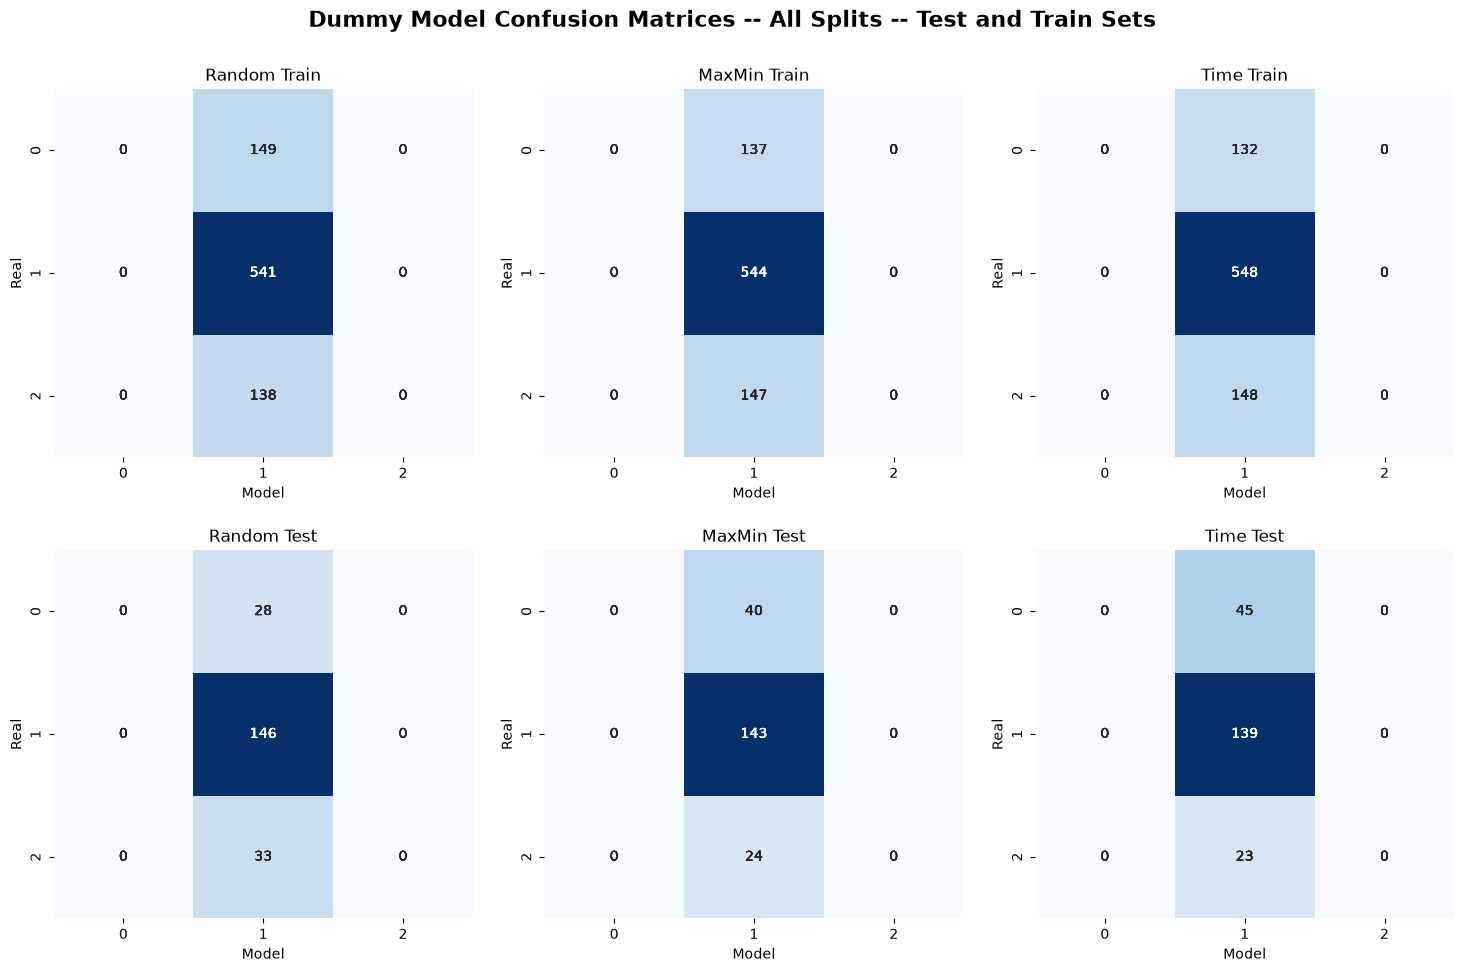

In [26]:
# UNFINISHED - function to plot confusion mtrx for a given model (all splits, test&train)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Dummy Model Confusion Matrices -- All Splits -- Test and Train Sets', fontsize=16, fontweight='bold')

descriptors_to_plot = ['Random Train', 'MaxMin Train', 'Time Train',
                        'Random Test', 'MaxMin Test', 'Time Test']

for i in enumerate(descriptors_to_plot):
    for i, descriptor in enumerate(descriptors_to_plot):
        row = i // 3
        col = i % 3

        if descriptor == "Random Train":
            cm = confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Train":
            cm = confusion_matrix(maxmin_train[TARGET], maxmin_dummy.predict(maxmin_train[MAXMIN_FEATURES]))
        elif descriptor == "Time Train":
            cm = confusion_matrix(time_train[TARGET], time_dummy.predict(time_train[TIME_FEATURES]))
        elif descriptor == "Random Test":
            cm = confusion_matrix(random_test[TARGET], random_dummy.predict(random_test[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Test":
            cm = confusion_matrix(maxmin_test[TARGET], maxmin_dummy.predict(maxmin_test[MAXMIN_FEATURES]))
        elif descriptor == "Time Test":
            cm = confusion_matrix(time_test[TARGET], time_dummy.predict(time_test[TIME_FEATURES]))

        sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', ax=axes[row, col], cbar=False)
        axes[row, col].set_title(descriptor)
        axes[row, col].set_ylabel("Real")
        axes[row, col].set_xlabel("Model")
    col = i % 3

plt.tight_layout(pad=2)
plt.show();

In [43]:
multilab_cm = multilabel_confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[RANDOM_FEATURES]))


#### Training Random Forest Model
Hyperparameters are tuned using 5-fold cross-validation, model with highest Matthews Correlation Coefficient (MCC) is selected.

In [27]:
# LINDA's random forest training model - FP size 
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, matthews_corrcoef
# Hyperparameters to compare
param_grid = {
   "n_estimators": [200, 500], #Number of decision trees in the forest. Build a forest with 200 or 500 decision trees.
   "max_depth": [None, 10, 20], # Allow no fixed depth limit, or at most 10 or 20 levels of splits along a path in each tree.
   "min_samples_leaf": [1, 2, 5], # Require at least 1, 2, or 5 training observations in every final leaf of a tree.
   "max_features": ["sqrt", 0.1, 1.0], #Consider about sqrt2048=45, 10% of 2048=204, or all 2,048 fingerprint features at each split.
   "class_weight": [None, "balanced"] #Give observations equal weight, or give minority-class observations higher weight.
}


# Preserve class proportions within each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) #shuffles observations before assigning them to folds.


rf_search = GridSearchCV(
   estimator=RandomForestClassifier(random_state=1147),
   param_grid=param_grid,
   scoring=make_scorer(matthews_corrcoef), #Tells it to evaluate predictions using MCC.
                                               #Higher MCC is better, so it selects the combination with the highest average validation MCC across five folds.
   cv=cv,
   n_jobs=-1,
   refit=True, #After finding the best combination, automatically trains that configuration on all of X_train and y_train.
   #verbose=2
)


rf_search.fit(random_train[RANDOM_FEATURES], random_train[TARGET])


# Best model is automatically retrained on all training data
best_rf = rf_search.best_estimator_


print("Best parameters:", rf_search.best_params_)
print("Best mean CV MCC:", rf_search.best_score_)
print(
   "CV MCC standard deviation:",
   rf_search.cv_results_["std_test_score"][rf_search.best_index_]
)



,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...om_state=1147)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [None, 'balanced'], 'max_depth': [None, 10, ...], 'max_features': ['sqrt', 0.1, ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(m...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated s

Best parameters: {'class_weight': None, 'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 200}
Best mean CV MCC: 0.36740546179296896
CV MCC standard deviation: 0.0469356864960858


Random Forest Classifier with 2048 bit fp

Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}

Best mean CV MCC: 0.3737438667207388

CV MCC standard deviation: 0.028817149252825896

In [28]:
# Generate 1024 bit fingerprints for all molecules
#create a morgan fingerprints data frame
morgan_gen_small = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

fingerprints = []
for mol in random_train['molecule']:
    fp = morgan_gen_small.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

# Convert to DataFrame with indexed column names
fp_columns = [f'Morgan_bit_{i}' for i in range(1024)]
fingerprint_df_small = pd.DataFrame(fingerprints, columns=fp_columns, index=random_train.index)
random_train_small = pd.concat([random_train, fingerprint_df_small], axis=1)

In [29]:
rf_search.fit(random_train_small[FEATURES], random_train_small[TARGET])


# Best model is automatically retrained on all training data
best_rf = rf_search.best_estimator_


print("Best parameters:", rf_search.best_params_)
print("Best mean CV MCC:", rf_search.best_score_)
print(
   "CV MCC standard deviation:",
   rf_search.cv_results_["std_test_score"][rf_search.best_index_]
)

NameError: name 'FEATURES' is not defined

Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 500}

Best mean CV MCC: 0.38601479239753955

CV MCC standard deviation: 0.046136984506446294

#### Train Kernel Model

Hyperparameters are tuned using 5-fold cross-validation, model with highest macrof1 is selected.

In [52]:
svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_SEED
)

svm_param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, "scale"]
}

grid_svm = GridSearchCV(
    svm,
    svm_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_svm.fit(fingerprint_df, df['ppdb_level'])

print(grid_svm.best_params_)
print(grid_svm.best_score_)

/home/ella/repos/che1147-bees/.venv/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/ella/repos/che1147-bees/.venv/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/ella/repos/che1147-bees/.venv/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/ella/repos/che1147-bees/.venv/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The

KeyboardInterrupt: 

In [53]:
from sklearn.feature_selection import VarianceThreshold

random_vt = VarianceThreshold(0)
maxmin_vt = VarianceThreshold(0)
time_vt = VarianceThreshold(0)

#define initial features
TARGET = "ppdb_level"
RANDOM_FEATURES = [col for col in random_train.columns if col.startswith("Morgan_bit_")]
MAXMIN_FEATURES = [col for col in maxmin_train.columns if col.startswith("Morgan_bit_")]
TIME_FEATURES = [col for col in time_train.columns if col.startswith("Morgan_bit_")]

random_vt.fit(random_train[RANDOM_FEATURES])
random_selected_cols = random_train.columns[random_vt.get_support(indices=True)]
random_train_filtered = random_train[random_selected_cols]
random_test_filtered = random_test[random_selected_cols]
RANDOM_FEATURES = [col for col in random_train_filtered.columns if col.startswith("Morgan_bit_")]
#random_train_filtered.head()

maxmin_vt.fit(maxmin_train[MAXMIN_FEATURES])
maxmin_selected_cols = maxmin_train.columns[maxmin_vt.get_support(indices=True)]
maxmin_train_filtered = maxmin_train[maxmin_selected_cols]
maxmin_test_filtered = maxmin_test[maxmin_selected_cols]
MAXMIN_FEATURES = [col for col in maxmin_train_filtered.columns if col.startswith("Morgan_bit_")]

time_vt.fit(time_train[TIME_FEATURES])
time_selected_cols = time_train.columns[time_vt.get_support(indices=True)]
time_train_filtered = time_train[time_selected_cols]
time_test_filtered = time_test[time_selected_cols]
TIME_FEATURES = [col for col in time_train_filtered.columns if col.startswith("Morgan_bit_")]

VarianceThreshold(threshold=0)

VarianceThreshold(threshold=0)

VarianceThreshold(threshold=0)

In [54]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_SEED,
    C=1,
    gamma='scale'
)

In [55]:
from sklearn.base import clone
# Fit independent models for each split

random_svc = clone(svm).fit(random_train[RANDOM_FEATURES], random_train[TARGET])
maxmin_svc = clone(svm).fit(maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
time_svc = clone(svm).fit(time_train[TIME_FEATURES], maxmin_train[TARGET])

#if creating loop
#create a list of dummy models 
svc_models = [
    ('random', random_svc),
    ('maxmin', maxmin_svc),
    ('time', time_svc),
]

# initialize dictionaries for error metrics
svc_results_test = {}
svc_results_train = {}

svc_results_test['random'] = get_regression_metrics(random_svc, random_test_filtered, random_test[RANDOM_FEATURES], random_test[TARGET])
svc_results_train['random'] = get_regression_metrics(random_svc, random_train_filtered, random_train[RANDOM_FEATURES], random_train[TARGET])
svc_results_test['maxmin'] = get_regression_metrics(maxmin_svc, maxmin_test_filtered, maxmin_test[MAXMIN_FEATURES], maxmin_test[TARGET])
svc_results_train['maxmin'] = get_regression_metrics(maxmin_svc, maxmin_train_filtered, maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
svc_results_test['time'] = get_regression_metrics(time_svc, time_test_filtered, time_test[TIME_FEATURES], time_test[TARGET])
svc_results_train['time'] = get_regression_metrics(time_svc, time_train_filtered, time_train[TIME_FEATURES], time_train[TARGET])

/home/ella/repos/che1147-bees/.venv/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/ella/repos/che1147-bees/.venv/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/ella/repos/che1147-bees/.venv/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [56]:
# Print the metrics for all models
print("SVC Results - All Splits -  Test and Train Sets")

for regressor_name, metrics in svc_results_train.items():
    print(f"\n\n Train Set -- {regressor_name} split:")
    for metric, value in metrics.items():
        print(f'{metric}:{value:.3f}', end=' ')

for regressor_name, metrics in svc_results_test.items():
    print(f"\n\n Test Set -- {regressor_name} split:")
    for metric, value in metrics.items():
        print(f'{metric}:{value:.3f}', end=' ')

SVC Results - All Splits -  Test and Train Sets


 Train Set -- random split:
F1:0.869 weighted F1:0.886 MCC:0.804 accuracy:0.883 precision:0.835 weighted precision:0.907 recall:0.925 weighted recall:0.883 

 Train Set -- maxmin split:
F1:0.846 weighted F1:0.868 MCC:0.777 accuracy:0.864 precision:0.810 weighted precision:0.898 recall:0.914 weighted recall:0.864 

 Train Set -- time split:
F1:0.314 weighted F1:0.444 MCC:-0.014 accuracy:0.414 precision:0.324 weighted precision:0.490 recall:0.320 weighted recall:0.414 

 Test Set -- random split:
F1:0.616 weighted F1:0.701 MCC:0.411 accuracy:0.686 precision:0.594 weighted precision:0.733 recall:0.660 weighted recall:0.686 

 Test Set -- maxmin split:
F1:0.511 weighted F1:0.643 MCC:0.201 accuracy:0.667 precision:0.566 weighted precision:0.636 recall:0.485 weighted recall:0.667 

 Test Set -- time split:
F1:0.284 weighted F1:0.437 MCC:-0.038 accuracy:0.401 precision:0.311 weighted precision:0.495 recall:0.290 weighted recall:0.401 

### Training using XGBoost
https://xgboost.readthedocs.io/en/stable/ 


In [31]:
bst = XGBClassifier(num_class= 3, n_estimators=13, max_depth=4, learning_rate=0.5, random_state = RANDOM_SEED)

random_bst = clone(bst).fit(random_train[RANDOM_FEATURES],random_train[TARGET])
maxmin_bst = clone(bst).fit(maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
time_bst = clone(bst).fit(time_train[TIME_FEATURES], time_train[TARGET])

#create a list of dummy models 
bst_models = [
    ('random', random_bst),
    ('maxmin', maxmin_bst),
    ('time', time_bst),
]

# initialize dictionaries for error metrics
bst_results_test = {} # initialize empty dictionary
bst_results_train = {}

bst_results_test['random'] = get_regression_metrics(random_bst, random_test, random_test[RANDOM_FEATURES], random_test[TARGET])
bst_results_train['random'] = get_regression_metrics(random_bst, random_train, random_train[RANDOM_FEATURES], random_train[TARGET])
bst_results_test['maxmin'] = get_regression_metrics(maxmin_bst, maxmin_test, maxmin_test[MAXMIN_FEATURES], maxmin_test[TARGET])
bst_results_train['maxmin'] = get_regression_metrics(maxmin_bst, maxmin_train, maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
bst_results_test['time'] = get_regression_metrics(time_bst, time_test, time_test[TIME_FEATURES], time_test[TARGET])
bst_results_train['time'] = get_regression_metrics(time_bst, time_train, time_train[TIME_FEATURES], time_train[TARGET])



In [42]:
#bst_results_test['random']
#bst_results_train['random']

#bst_results_test['maxmin']
#bst_results_train['maxmin']

bst_results_test['time']
#bst_results_train['time']


{'F1': 0.4894855001559379,
 'weighted F1': 0.6360918315003945,
 'MCC': 0.34109619990533036,
 'accuracy': 0.7198067632850241,
 'precision': 0.8275908119658119,
 'weighted precision': 0.7820028954539825,
 'recall': 0.4882795213104878,
 'weighted recall': 0.7198067632850241}

In [33]:
# 
def confusion_plots(random_model, maxmin_model, time_model, name_string):
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f"{name_string} Model Confusion Matrices -- All Splits -- Test and Train Sets", fontsize=16, fontweight='bold')

    descriptors_to_plot = ['Random Train', 'MaxMin Train', 'Time Train',
                        'Random Test', 'MaxMin Test', 'Time Test']

    for i in enumerate(descriptors_to_plot):
        for i, descriptor in enumerate(descriptors_to_plot):
            row = i // 3
            col = i % 3

            if descriptor == "Random Train":
                cm = confusion_matrix(random_train[TARGET], random_model.predict(random_train[RANDOM_FEATURES]))
            elif descriptor == "MaxMin Train":
                cm = confusion_matrix(maxmin_train[TARGET], maxmin_model.predict(maxmin_train[MAXMIN_FEATURES]))
            elif descriptor == "Time Train":
                cm = confusion_matrix(time_train[TARGET], time_model.predict(time_train[TIME_FEATURES]))
            elif descriptor == "Random Test":
                cm = confusion_matrix(random_test[TARGET], random_model.predict(random_test[RANDOM_FEATURES]))
            elif descriptor == "MaxMin Test":
                cm = confusion_matrix(maxmin_test[TARGET], maxmin_model.predict(maxmin_test[MAXMIN_FEATURES]))
            elif descriptor == "Time Test":
                cm = confusion_matrix(time_test[TARGET], time_model.predict(time_test[TIME_FEATURES]))

            sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', ax=axes[row, col], cbar=False)
            axes[row, col].set_title(descriptor)
            axes[row, col].set_ylabel("Real")
            axes[row, col].set_xlabel("Model")
        col = i % 3

    plt.tight_layout(pad=2)
    plt.show();

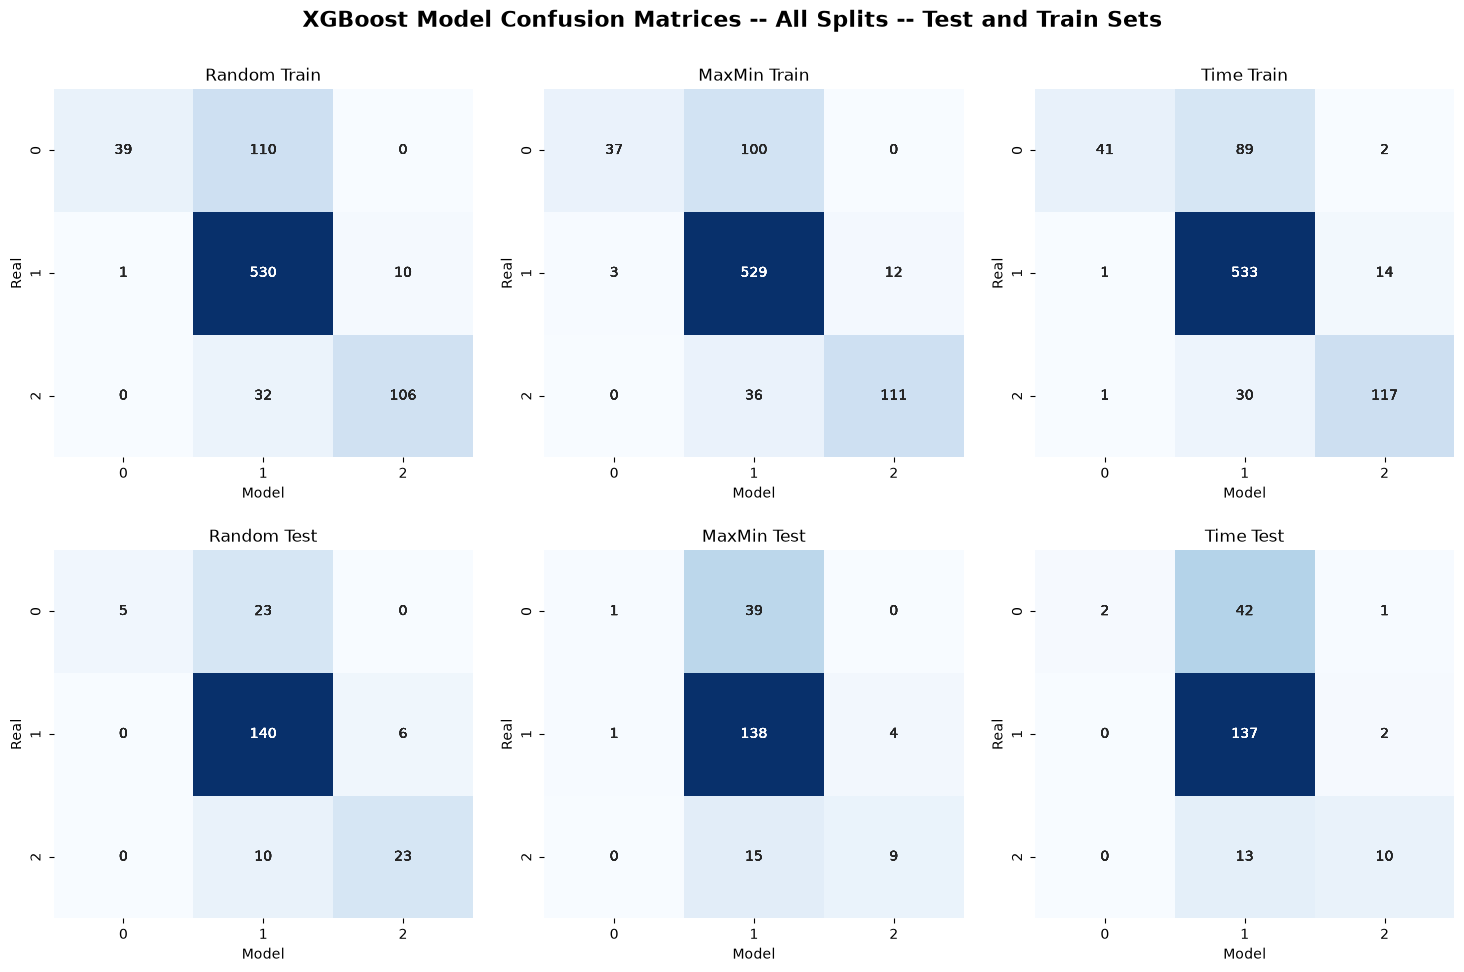

In [34]:
confusion_plots(random_bst, maxmin_bst, time_bst, 'XGBoost')

### Training using TabPFN
https://github.com/PriorLabs/tabpfn 

In [89]:
%pip install tabpfn
from tabpfn import TabPFNClassifier, TabPFNRegressor

tab = TabPFNClassifier()
tab_random = tab.fit(random_train[RANDOM_FEATURES], random_train[TARGET])  # downloads checkpoint on first use
predictions = tab.predict(random_test)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 905.9/905.9 kB 20.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 12.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 18.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 22.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 671.8/671.8 kB 16.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 MB 24.7 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [tabpfn]15/16 [tabpfn]face-hub]
Note: you may need to restart the kernel to use updated packages.


TabPFNLicenseError: TabPFN requires a one-time license acceptance to download model weights
for local inference. Your datasets stay local and are never sent to Prior
Labs, and TabPFN works offline once the weights are downloaded.

There is no interactive terminal available.

To authenticate in a non-interactive environment:
  1. Open https://ux.priorlabs.ai in a browser and log in (or register)
  2. Accept the license on the Licenses tab
  3. Copy your API Key from https://ux.priorlabs.ai/account
  4. Set the environment variable: export TABPFN_TOKEN="<your-api-key>"
     or in Python (before calling .fit()): import os; os.environ["TABPFN_TOKEN"] = "<your-api-key>"

### Model Evaluation
For all models, the following are reported:
Macro F1, MCC, precision, accuracy, recall, balanced accuracy, per-class precision and recall. Confusion matrices are also generated. 

### Further Data Analysis and Considerations
Addressing class imbalance: partial undersampling of majority class (apply to training portion of each cross-validation fold), class weighting.

Precision vs. Recall Tradeoff: affected by cutoff value used for logistic regression (sigmoid parameter). Will need to see if this parameter is tunable for the multiclass version. This parameter can be related to the FP/FN ratio, which can be tuned to suit use-cases/goals which differ in being more or less conservative in their predictions of compound toxicity.

| FP/FN (ratio) | plain language | drawback |
|-|-|-|
| higher | Agrochemicals that are o.k. for bees are recommended as 'do not use' | limits design space of agrochemicals|
| low | Agrochemicals which are harmful for bees are recommended as 'o.k. to use' | harms bees |